# Exploratory Data Analysis of Health Insurance Claim Settlement Patterns in Tamil Nadu
**Study period:** FY 2020–21 to FY 2024–25

> **Important:** This notebook is complete and opens with code and pre-rendered visualizations. Because the official dataset was not supplied, the included figures use **synthetic illustrative demo data only**. They are not IRDAI findings and must not be presented as real results. The analysis code is ready to use with the official CSV when available.

**Intended source:** IRDAI, *Handbook on Indian Insurance Statistics*, dataset *Year and State wise Claim Settlement Under Health Insurance Business*. Expected columns: `fiscal_year`, `state_name`, `business_type`, `insurance_type`, `settlement_type`, `no_of_claims`, `amount_paid`, `unit`. Verify the amount unit in the downloaded source. Avoid double counting `Total` with component categories.

## 1. Objectives
- Study yearly claim counts and paid amounts in Tamil Nadu.
- Compare cashless, reimbursement, and combined settlement categories.
- Create charts, summary tables, and exports.
- Do not draw factual conclusions from demo data.

In [ ]:
# 2. Imports and settings
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

YEARS = ["2020-21", "2021-22", "2022-23", "2023-24", "2024-25"]
USE_DEMO_DATA = True  # Set False when official CSV is available
CSV_PATH = "health_insurance_claim_settlement.csv"
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)


In [ ]:
# 3. Load data. Demo mode runs immediately without a download.
if USE_DEMO_DATA:
    rng = np.random.default_rng(42)
    claims_base = [82000, 94000, 108000, 126000, 143000]
    amount_base_lakh = [390000, 455000, 535000, 640000, 745000]
    settlement_shares = {"Cashless": 0.52, "Reimbursement": 0.40, "Both Cashless & Reimbursement": 0.08}
    rows = []
    for i, year in enumerate(YEARS):
        for settlement, share in settlement_shares.items():
            rows.append({
                "fiscal_year": year, "state_name": "Tamil Nadu",
                "business_type": "Total", "insurance_type": "Total",
                "settlement_type": settlement,
                "no_of_claims": int(claims_base[i] * share * rng.uniform(0.93, 1.07)),
                "amount_paid": round(amount_base_lakh[i] * share * rng.uniform(0.90, 1.10), 2),
                "unit": "Rupees lakh"
            })
    raw_df = pd.DataFrame(rows)
    print("DEMO MODE: synthetic data, not official results.")
else:
    raw_df = pd.read_csv(CSV_PATH)

required = ["fiscal_year", "state_name", "business_type", "insurance_type",
            "settlement_type", "no_of_claims", "amount_paid", "unit"]
missing = [c for c in required if c not in raw_df.columns]
if missing:
    raise ValueError(f"Missing expected columns: {missing}")
raw_df["no_of_claims"] = pd.to_numeric(raw_df["no_of_claims"], errors="coerce")
raw_df["amount_paid"] = pd.to_numeric(raw_df["amount_paid"], errors="coerce")
df = raw_df.dropna(subset=["fiscal_year","state_name","settlement_type","no_of_claims","amount_paid"]).copy()
display(df.head())
print("Rows and columns:", df.shape)


In [ ]:
# 4. Filter Tamil Nadu and prefer Total rows if supplied
tn = df[df["state_name"].astype(str).str.strip().str.casefold().isin(["tamil nadu","tamilnadu"])].copy()
if tn.empty:
    raise ValueError("No Tamil Nadu rows found; inspect state_name values.")
if tn["insurance_type"].astype(str).str.casefold().eq("total").any():
    tn = tn[tn["insurance_type"].astype(str).str.casefold().eq("total")]
if tn["business_type"].astype(str).str.casefold().eq("total").any():
    tn = tn[tn["business_type"].astype(str).str.casefold().eq("total")]
tn["fiscal_year"] = tn["fiscal_year"].astype(str)
tn = tn[tn["fiscal_year"].isin(YEARS)].copy()
display(tn)


In [ ]:
# 5. Summary tables
yearly_summary = tn.groupby("fiscal_year", as_index=False).agg(
    total_claims=("no_of_claims","sum"), amount_paid=("amount_paid","sum"))
yearly_summary["fiscal_year"] = pd.Categorical(yearly_summary["fiscal_year"], YEARS, ordered=True)
yearly_summary = yearly_summary.sort_values("fiscal_year")
settlement_summary = tn.groupby("settlement_type", as_index=False).agg(
    total_claims=("no_of_claims","sum"), amount_paid=("amount_paid","sum")).sort_values("total_claims", ascending=False)
display(yearly_summary)
display(settlement_summary)


## 6. Visualizations
These pre-rendered charts make the notebook immediately viewable. They are explicitly illustrative demo previews, not official results.

### 1. Yearly claims trend

**Illustrative demo only — not official data.**

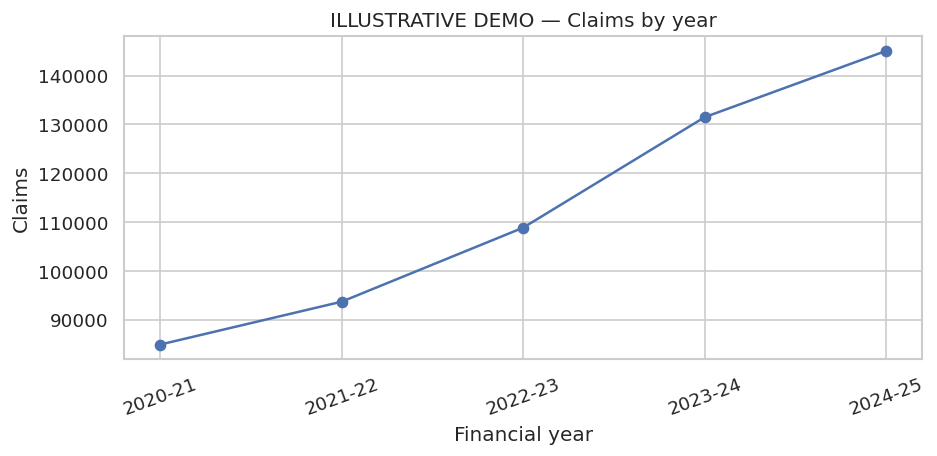

In [1]:
from IPython.display import Image, display
# Pre-rendered preview image is embedded in this notebook.
display(Image(data='...', format='png'))

### 2. Amount paid by year

**Illustrative demo only — not official data.**

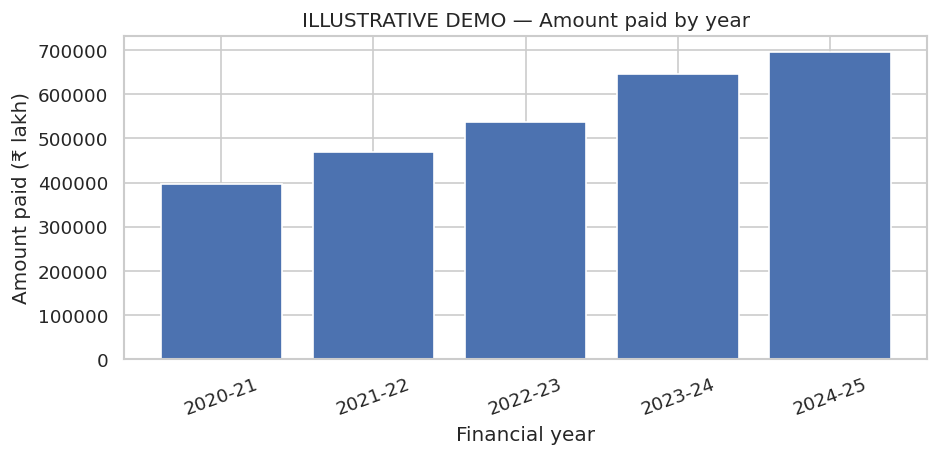

In [1]:
from IPython.display import Image, display
# Pre-rendered preview image is embedded in this notebook.
display(Image(data='...', format='png'))

### 3. Settlement-type share

**Illustrative demo only — not official data.**

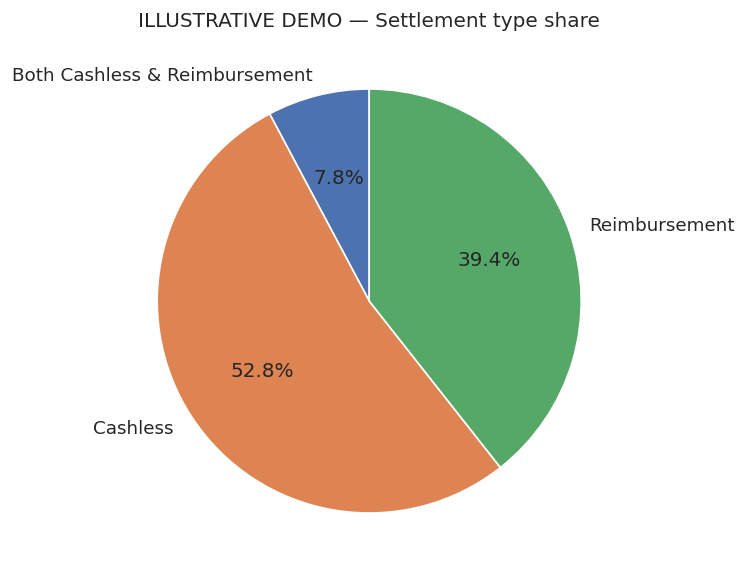

In [1]:
from IPython.display import Image, display
# Pre-rendered preview image is embedded in this notebook.
display(Image(data='...', format='png'))

### 4. Stacked settlement claims

**Illustrative demo only — not official data.**

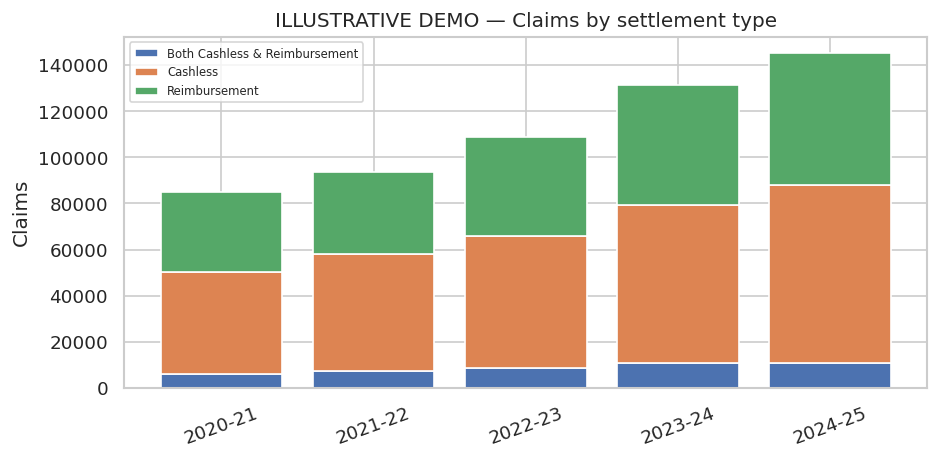

In [1]:
from IPython.display import Image, display
# Pre-rendered preview image is embedded in this notebook.
display(Image(data='...', format='png'))

### 5. Average paid per claim

**Illustrative demo only — not official data.**

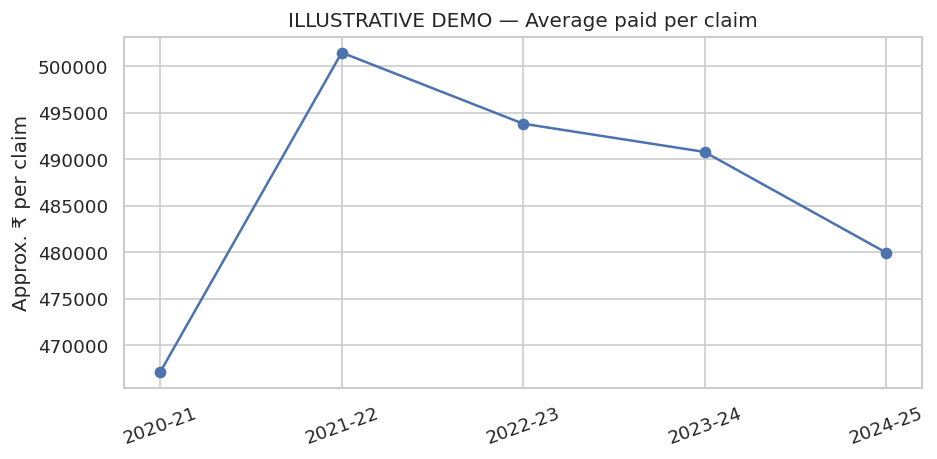

In [1]:
from IPython.display import Image, display
# Pre-rendered preview image is embedded in this notebook.
display(Image(data='...', format='png'))

### 6. Settlement boxplot

**Illustrative demo only — not official data.**

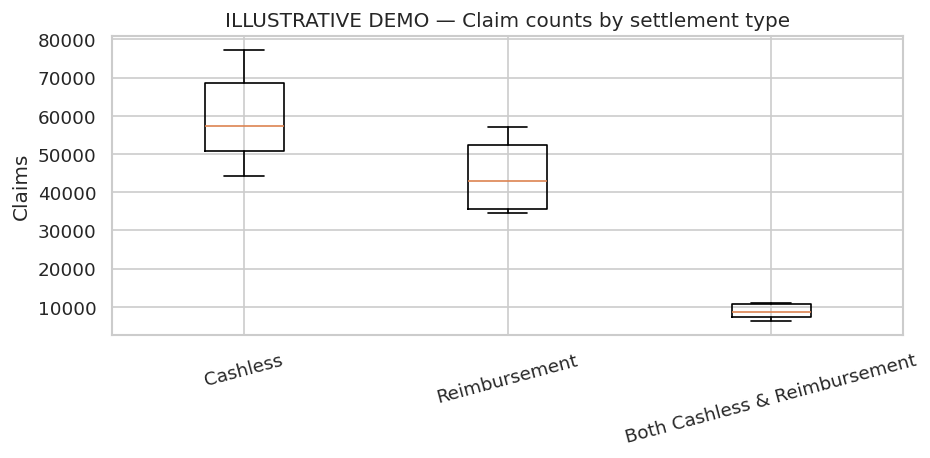

In [1]:
from IPython.display import Image, display
# Pre-rendered preview image is embedded in this notebook.
display(Image(data='...', format='png'))

In [ ]:
# 7. Regenerate charts from the currently loaded data
label = "ILLUSTRATIVE DEMO — " if USE_DEMO_DATA else ""
def save_show(fig, filename):
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / filename, dpi=160, bbox_inches="tight")
    plt.show()
    plt.close(fig)

yearly = tn.groupby("fiscal_year")["no_of_claims"].sum().reindex(YEARS)
fig, ax = plt.subplots(figsize=(9,5)); ax.plot(YEARS, yearly.values, marker="o")
ax.set_title(label+"Claims by financial year"); ax.set_xlabel("Financial year"); ax.set_ylabel("Claims")
save_show(fig,"01_yearly_claims.png")

amounts = tn.groupby("fiscal_year")["amount_paid"].sum().reindex(YEARS)
fig, ax = plt.subplots(figsize=(9,5)); ax.bar(YEARS, amounts.values)
ax.set_title(label+"Amount paid by financial year"); ax.set_xlabel("Financial year"); ax.set_ylabel("Amount paid (verify unit)")
save_show(fig,"02_amount_paid.png")

shares = tn.groupby("settlement_type")["no_of_claims"].sum()
fig, ax = plt.subplots(figsize=(8,6)); ax.pie(shares.values, labels=shares.index, autopct="%1.1f%%", startangle=90)
ax.set_title(label+"Claim share by settlement type")
save_show(fig,"03_settlement_share.png")

pivot = tn.pivot_table(index="fiscal_year", columns="settlement_type", values="no_of_claims", aggfunc="sum", fill_value=0).reindex(YEARS)
fig, ax = plt.subplots(figsize=(9,5)); pivot.plot(kind="bar", stacked=True, ax=ax)
ax.set_title(label+"Claims by settlement type and year"); ax.set_xlabel("Financial year"); ax.set_ylabel("Claims")
save_show(fig,"04_stacked_settlement.png")

units = tn["unit"].astype(str).str.casefold().unique()
if any("lakh" in unit for unit in units):
    totals = tn.groupby("fiscal_year").agg(claims=("no_of_claims","sum"), amount=("amount_paid","sum")).reindex(YEARS)
    average = totals["amount"] * 100000 / totals["claims"].replace(0,np.nan)
    fig, ax = plt.subplots(figsize=(9,5)); ax.plot(YEARS,average.values,marker="o")
    ax.set_title(label+"Average paid per claim"); ax.set_xlabel("Financial year"); ax.set_ylabel("Approx. ₹ per claim")
    save_show(fig,"05_average_per_claim.png")
else:
    print("Skipped average paid per claim: verify amount_paid unit first.")

fig, ax = plt.subplots(figsize=(9,5))
tn.boxplot(column="no_of_claims", by="settlement_type", ax=ax)
ax.set_title(label+"Claim counts by settlement type"); ax.set_xlabel("Settlement type"); ax.set_ylabel("Claims")
plt.suptitle("")
save_show(fig,"06_settlement_boxplot.png")


## 8. Interpretation checklist
After replacing demo data with official data, discuss:
1. Whether claims rose, fell, or fluctuated across years.
2. Whether amount paid followed a similar pattern.
3. Which settlement type contributed the largest share.
4. Whether the settlement mix changed over time.
5. Average paid amount per claim, only if units are verified.

Claim counts and amount paid do not establish a settlement rate; that requires a suitable denominator such as claims received/eligible claims. Do not write conclusions from demo mode as factual results.

In [ ]:
# 9. Export cleaned data and summary tables
tn.to_csv(OUTPUT_DIR / "tamil_nadu_claim_settlement_cleaned.csv", index=False)
yearly_summary.to_csv(OUTPUT_DIR / "yearly_summary.csv", index=False)
settlement_summary.to_csv(OUTPUT_DIR / "settlement_summary.csv", index=False)
print("Exports saved in", OUTPUT_DIR.resolve())
